# Creating a Neural Network to classify diabetic patients

<img src="https://www.ndr.de/diabetes312_v-fullhd.jpg" align="left" width="600">

## Libraries and settings

In [1]:
# Libraries
import os
import platform
import warnings
from datetime import datetime
from platform import python_version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ignore warnings
warnings.filterwarnings('ignore')

# Show current working directory
print(os.getcwd())

/workspaces/python_machine_learning_basics/08_Neural_Networks


<h3>The Problem</h3>
<p>Suppose we have some information about obesity, smoking habits, and exercise habits of five people. We also know whether these people are diabetic or not. The dataset looks like this:</p>
<table class="table table-striped">
    <thead>
        <tr>
            <th>Person</th>
            <th>Smoking</th>
            <th>Obesity</th>
            <th>Exercise</th>
            <th>Diabetic</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td>Person 1</td>
            <td>0</td>
            <td>1</td>
            <td>0</td>
            <td>1</td>
        </tr>
        <tr>
            <td>Person 2</td>
            <td>0</td>
            <td>0</td>
            <td>1</td>
            <td>0</td>
        </tr>
        <tr>
            <td>Person 3</td>
            <td>1</td>
            <td>0</td>
            <td>0</td>
            <td>0</td>
        </tr>
        <tr>
            <td>Person 4</td>
            <td>1</td>
            <td>1</td>
            <td>0</td>
            <td>1</td>
        </tr>
        <tr>
            <td>Person 5</td>
            <td>1</td>
            <td>1</td>
            <td>1</td>
            <td>1</td>
        </tr>
    </tbody>
</table>
<p>In this table, there are five columns: Person, Smoking, Obesity, Exercise, and Diabetic. Here 1 refers to true and 0 refers to false. For instance, the first person has values of 0, 1, 0 which means that the person doesn't smoke, is obese, and doesn't exercise. The person is also diabetic. It is clearly evident from the dataset that a person's obesity is indicative of him being diabetic. Our task is to create a neural network that is able to predict whether an unknown person is diabetic or not given data about his exercise habits, obesity, and smoking habits.</p>

### AUFGABE UND KONTEXT:

- Dieses Notebook zeigt **Schritt für Schritt, wie ein einzelnes künstliches Neuron lernt**, ohne Keras zu verwenden. Ziel ist eine binäre Klassifikation: `Diabetic = 1` für Diabetes, `0` für kein Diabetes.
- Die fünf künstlichen Beispieldatensätze enthalten drei Eingaben: **Smoking, Obesity und Exercise**, jeweils als 0 oder 1. `X` enthält diese Merkmale, `y` den Diabetesstatus. Im Beispiel stimmt dieser Status immer mit `Obesity` überein.

- Das Modell berechnet zuerst die gewichtete Summe **`XW = X @ weights + bias`**. Die drei Gewichte bestimmen den Einfluss der Eingaben; der Bias verschiebt den Ausgangswert.
- Die **Sigmoidfunktion** wandelt diese Summe in einen Wert zwischen 0 und 1 um, der als geschätzte Wahrscheinlichkeit für Klasse 1 interpretiert wird. Ihre Ableitung wird für die Gewichtsanpassung benötigt; beide Funktionen werden dargestellt.
- Gewichte und Bias werden zufällig initialisiert. `np.random.seed(42)` macht die Startwerte reproduzierbar; die **Lernrate 0.25** bestimmt die Schrittgrösse der Anpassungen.

- Zuerst wird ein Lernschritt einzeln vorgerechnet: Vorhersage berechnen, **`error = z - y`** bestimmen und daraus mit der Sigmoid-Ableitung die Gradienten berechnen. Anschliessend werden Gewichte und Bias entgegen der Gradientenrichtung angepasst. Diese Rechnung entspricht dem Minimieren einer quadratischen Fehlerfunktion.
- Danach wiederholt die Schleife diesen Ablauf über **200 Epochen**, jeweils mit allen fünf Personen. Wird die vorherige Demonstrationszelle ausgeführt, startet die Schleife mit den bereits einmal angepassten Gewichten.
- Der Fehlerplot zeigt **die Summe der vorzeichenbehafteten Abweichungen** (`error.sum()`), keinen MSE. Positive und negative Fehler können sich aufheben; ein Wert nahe 0 beweist deshalb keine guten Einzelvorhersagen.

- Abschliessend berechnet das trainierte Modell einen Wahrscheinlichkeitswert für **`[0, 1, 0]`**: nicht rauchend, adipös, keine Bewegung. Diese Merkmalskombination kommt bereits im Training vor.
- Es gibt **keine getrennten Testdaten**. Das Notebook veranschaulicht den Lernmechanismus; es belegt weder die Vorhersagequalität bei unbekannten Personen noch medizinische Zusammenhänge.

VERLANGT: Die Zellen in ihrer Reihenfolge ausführen und nachvollziehen, wie Vorwärtsrechnung, Fehlerberechnung und Gradientenabstieg die Modellparameter verändern. Anschliessend den Fehlerplot und die abschliessende Vorhersage unter den genannten Einschränkungen interpretieren

In [2]:
# Function: sigmoid activation, converts a value into a number in (0, 1)
def sigmoid(x):                                             #Definiert die Aktivierungsfunktion für die gewichtete Summe der Eingaben
    """Sigmoid activation function."""
    return 1 / (1 + np.exp(-x))                             #Wandelt x in einen Wert zwischen 0 und 1 um, hier als geschätzte Diabeteswahrscheinlichkeit

# Function: slope of the sigmoid, tells how much to change the weights
def sigmoid_der(x):                                         #Definiert die Ableitung: wie stark sich die Sigmoid-Ausgabe bei einer Änderung von x verändert
    """Derivative of the sigmoid function."""
    return sigmoid(x) * (1 - sigmoid(x))                    #Berechnet die Steigung; wird später mit dem Fehler kombiniert, um Gewichte und Bias anzupassen

In [3]:
# Create data frame
data = np.array(                                                            #Erstellt die Beispieldaten für fünf Personen; 1 = ja, 0 = nein
    [[0, 1, 0, 1], [0, 0, 1, 0], [1, 0, 0, 0], [1, 1, 0, 1], [1, 1, 1, 1]]  #Jede Zeile enthält Rauchen, Adipositas, Bewegung und Diabetesstatus einer Person
)
df = pd.DataFrame(data, columns=['Smoking', 'Obesity', 'Exercise', 'Diabetic']) #Erstellt eine Tabelle mit verständlichen Spaltennamen
print(df)                                                                       #Zeigt die fünf Personen und ihre Merkmale zur Kontrolle

# Features X (first three columns) and labels y (last column, as a column)
X = data[:, 0:3]                                                                #Wählt alle Zeilen und die ersten drei Spalten als Eingaben; Form: (5, 3)
y = data[:, 3].reshape(5, 1)                             #Wählt den Diabetesstatus und formt ihn zum Spaltenvektor; Form: (5, 1), passend zur Modellausgabe

   Smoking  Obesity  Exercise  Diabetic
0        0        1         0         1
1        0        0         1         0
2        1        0         0         0
3        1        1         0         1
4        1        1         1         1


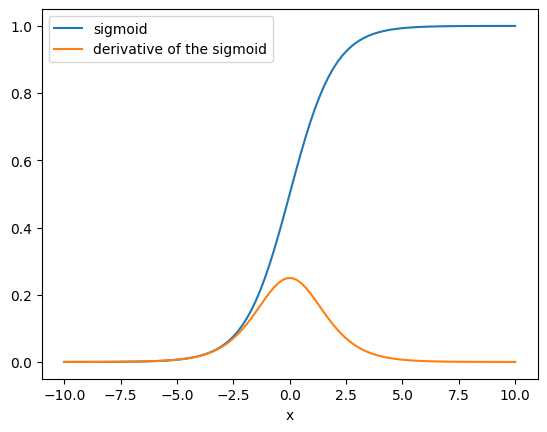

In [4]:
# Figure showing the sigmoid function and its derivative
z = np.linspace(-10, 10, 100)                                   #Erstellt 100 gleichmässig verteilte x-Werte von −10 bis 10 für die Darstellung
plt.plot(z, sigmoid(z), label='sigmoid')                        #Zeichnet die S-Kurve: wandelt Eingaben in Werte zwischen 0 und 1 um
plt.plot(z, sigmoid_der(z), label='derivative of the sigmoid')  #Zeichnet die Steigung: bei 0 am grössten, bei stark negativen oder positiven Werten nahe 0
plt.xlabel('x')                                                 #Beschriftet die horizontale Achse mit der Eingabe der Sigmoidfunktion
plt.legend()                                                    #Zeigt die Beschriftungen zur Unterscheidung der beiden Kurven
plt.show()                                                      #Zeigt Sigmoidfunktion und Ableitung gemeinsam an

In [5]:
# Initialize weights and bias & define learning rate und the number of epochs
np.random.seed(42)                      #Legt den Zufallsstart fest, damit bei erneuter Ausführung dieselben Anfangswerte entstehen
weights = np.random.rand(3, 1)          #Erstellt drei zufällige Startgewichte zwischen 0 und 1: eines pro Eingabemerkmal
bias = np.random.rand(1)                #Erstellt einen zufälligen Bias; dieser wird zur gewichteten Summe jeder Person addiert
learning_rate = 0.25                    #Legt die Schrittgrösse fest, mit der Gewichte und Bias beim Lernen angepasst werden
num_epochs = 200                        #Legt fest, dass die Trainingsschleife die fünf Personen später 200-mal verarbeitet

In [6]:
# Calculations step by step: data, weights and bias
print('X:', '\n', X, '\n')                                      #Zeigt die drei Eingabemerkmale jeder Person; \n erzeugt Zeilenumbrüche
print('y:', '\n', y, '\n')                                      #Zeigt die tatsächlichen Zielwerte: 1 = Diabetes, 0 = kein Diabetes
print('weights:', '\n', weights, '\n')                          #Zeigt die aktuellen Gewichte für Rauchen, Adipositas und Bewegung
print('bias:', '\n', bias, '\n')                                #Zeigt den gemeinsamen Zusatzwert zur gewichteten Summe

# Calculate X * weights + bias
XW = np.dot(X, weights) + bias                                  #Multipliziert pro Person jedes Merkmal mit seinem Gewicht, summiert und addiert den Bias
print('XW:', '\n', XW, '\n')                                    #Zeigt die fünf gewichteten Summen vor der Aktivierung

# Apply the activation function to XW
z = sigmoid(XW)                                                 #Wandelt jede gewichtete Summe in eine geschätzte Wahrscheinlichkeit zwischen 0 und 1 um
print('sigmoid(XW) = z', '\n', z, '\n')                         #Zeigt die aktuellen Vorhersagen für die fünf Personen

# Calculate the error (difference between z and the labels)
error = z - y                                                   #Berechnet die Abweichung: positiv = Vorhersage zu hoch, negativ = zu niedrig
print('error:', '\n', error, '\n')                              #Zeigt die Abweichung für jede Person einzeln

# Backpropagation: derivative of the activation function at XW
dpred_dz = sigmoid_der(XW)                                      #Berechnet, wie empfindlich die Vorhersage auf eine Änderung der gewichteten Summe reagiert
print('sigmoid_der(XW):', '\n', dpred_dz, '\n')                 #Zeigt die Sigmoid-Steigung an den fünf aktuellen gewichteten Summen

# Calculate the delta of z (chain rule)
z_delta = error * dpred_dz                                      #Verknüpft Fehler und Steigung per Kettenregel zum Gradienten von ½ × Fehler² bezüglich XW
print('z_delta:', '\n', z_delta, '\n')                          #Zeigt den Beitrag jeder Person zur anschliessenden Parameteranpassung

# Adapt weights
weights = weights - learning_rate * np.dot(X.T, z_delta)        #Summiert mit X.T die Gradientenbeiträge pro Merkmal und passt die Gewichte entgegen 
                                                                #dem Gradienten an
print('adapted weights', '\n', weights, '\n')                   #Zeigt die drei Gewichte nach diesem Lernschritt

# Adapt bias
bias = bias - learning_rate * np.sum(z_delta)                   #Summiert die Beiträge aller Personen und passt den gemeinsamen Bias entgegen dem Gradienten an
print('adapted bias:', '\n', bias)                              #Zeigt den Bias nach diesem Lernschritt

X: 
 [[0 1 0]
 [0 0 1]
 [1 0 0]
 [1 1 0]
 [1 1 1]] 

y: 
 [[1]
 [0]
 [0]
 [1]
 [1]] 

weights: 
 [[0.37454012]
 [0.95071431]
 [0.73199394]] 

bias: 
 [0.59865848] 

XW: 
 [[1.54937279]
 [1.33065243]
 [0.9731986 ]
 [1.92391291]
 [2.65590685]] 

sigmoid(XW) = z 
 [[0.82482312]
 [0.79094853]
 [0.72575659]
 [0.87257414]
 [0.93437412]] 

error: 
 [[-0.17517688]
 [ 0.79094853]
 [ 0.72575659]
 [-0.12742586]
 [-0.06562588]] 

sigmoid_der(XW): 
 [[0.14448994]
 [0.16534895]
 [0.19903396]
 [0.11118851]
 [0.06131912]] 

z_delta: 
 [[-0.0253113 ]
 [ 0.13078251]
 [ 0.14445021]
 [-0.01416829]
 [-0.00402412]] 

adapted weights 
 [[0.34297567]
 [0.96159023]
 [0.70030434]] 

adapted bias: 
 [0.54072623]


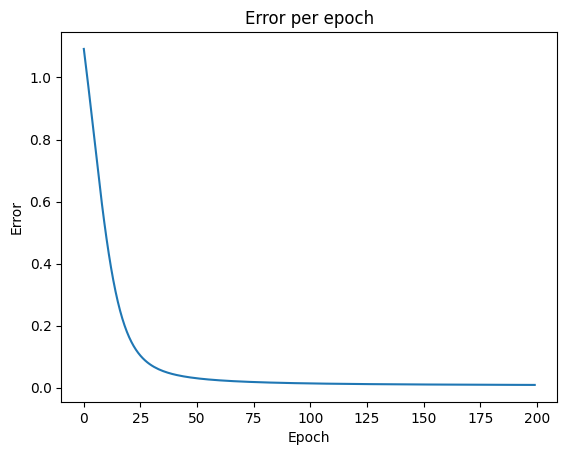

In [7]:
# Neural network: train for num_epochs epochs and store the error
errors = []                                                 #Erstellt eine Liste für die Fehlersumme jeder Epoche
for epoch in range(num_epochs):                             #Wiederholt das Lernen 200-mal; startet mit den aktuell gespeicherten Gewichten und dem Bias
    # Forward pass: X * weights + bias, then the activation function
    XW = np.dot(X, weights) + bias                          #Berechnet die gewichtete Summe plus Bias für alle fünf Personen
    z = sigmoid(XW)                                         #Wandelt die Summen in geschätzte Wahrscheinlichkeiten für Diabetes um

    # Error (difference between z and the labels)
    error = z - y                                           #Berechnet pro Person die Abweichung zwischen Vorhersage und tatsächlichem Zielwert
    errors.append(error.sum())                              #Speichert die vorzeichenbehaftete Fehlersumme; positive und negative Fehler können sich aufheben

    # Backpropagation: change weights and bias
    z_delta = error * sigmoid_der(XW)                        #Kombiniert Fehler und Sigmoid-Steigung per Kettenregel für die Gradientenberechnung
    weights = weights - learning_rate * np.dot(X.T, z_delta) #Passt jedes Gewicht anhand der summierten Gradientenbeiträge aller Personen an
    bias = bias - learning_rate * np.sum(z_delta)            #Passt den gemeinsamen Bias anhand der summierten Beiträge an

# Figure showing the error per epoch
plt.plot(errors)                                            #Zeichnet die gespeicherte Fehlersumme pro Epoche; dies ist kein MSE
plt.xlabel('Epoch')                                         #Beschriftet die x-Achse mit den Trainingsepochen
plt.ylabel('Error')                                         #Beschriftet die y-Achse mit der vorzeichenbehafteten Fehlersumme
plt.title('Error per epoch')                                #Setzt den Diagrammtitel
plt.show()                                                  #Zeigt den Verlauf; eine Summe nahe 0 garantiert keine kleinen Einzelfehler

In [8]:
# Model prediction based on new data
data_new = np.array([[0, 1, 0]])                                 #Beschreibt eine Person: raucht nicht, ist adipös, macht keine Bewegung; Form (1, 3)
df_new = pd.DataFrame(data_new, columns=['Smoking', 'Obesity', 'Exercise']) # Erstellt eine beschriftete Tabelle zur Kontrolle der Eingaben
print('New data (basis for prediction):')                        #Beschriftet die Ausgabe der verwendeten Personendaten
print(df_new)                                                    #Zeigt die drei Merkmale; diese Kombination kam bereits im Training vor

# Calculate the probability of having diabetes
result = sigmoid(np.dot(data_new, weights) + bias)               #Berechnet mit den gelernten Gewichten und dem Bias die geschätzte Diabeteswahrscheinlichkeit
print('Predicted probability of having diabetes:', result.round(3))   #Gibt den Wert auf drei Dezimalstellen aus; beispielsweise bedeutet 0.9 
                                                                      #eine Modellschätzung von 90 %

New data (basis for prediction):
   Smoking  Obesity  Exercise
0        0        1         0
Predicted probability of having diabetes: [[0.926]]


### Jupyter notebook --footer info-- (please always provide this at the end of each submitted notebook)

In [9]:
# Show operating system, date/time and Python version
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-10-26 07:26:03
Python Version: 3.11.17
-----------------------------------
